# Cameron Peak and East Troublesome Fire Burn Severity
## Burn Severity in the Wildland Urban Interface

- **Objective:**
For this notebook, the Key and Benson burn severity classes from 02_burn_severity are compared with the Wildland Urban Interface (WUI) map from 01_data_download, to find how much of the high severity area of the 2020 Cameron Peak and East Troublesome fires was in or near homes.

- **Objective goals:**
    - Match the WUI map to the 30m burn severity grid
    - Compare the burn severity in the WUI with the land around it
    - Find how much of the high severity area was in the WUI or close enough for embers to reach it
    - Map the high severity area near the WUI and save the tables

---

### Methodology

#### 1. Match the WUI Map to the Burn Severity Grid
- Resample the WUI map to each fire's 30m grid

#### 2. Burn Severity in the WUI
- Find the area of each burn severity class in the WUI and outside it, inside the perimeters

#### 3. High Severity in or Near the WUI
- Find the distance from the high severity area to the WUI
- Map the high severity area in the WUI, within 2.4km of it, and farther away

#### 4. Save the Results
- Save the area tables

#### 5. Summary
- Sum up how much of the high severity area was in or near the WUI

# Libraries

In [1]:
### file paths, OS operations, utilities
import os
import pathlib

### data handling
import numpy as np
import pandas as pd
import geopandas as gpd

### rasters
import rioxarray as rxr
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from scipy.ndimage import distance_transform_edt

### visualization
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Primary Directory

In [2]:
### set up root file path
# Walk up from the current directory to find the repo root (contains .git)
_cwd = pathlib.Path(os.getcwd()).resolve()
repo_root = next(
    (p for p in [_cwd] + list(_cwd.parents) if (p / '.git').exists()),
    _cwd
)
os.chdir(repo_root)

data_dir = os.path.join(repo_root, 'data')
os.makedirs(data_dir, exist_ok=True)

print('Repo root:', repo_root)

Repo root: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity


# Secondary Directories

In [3]:
### set a directory for the WUI burn severity results
wui_severity_dir = os.path.join(data_dir, 'wui_severity')
os.makedirs(wui_severity_dir, exist_ok=True)

# Load the Saved Data
These are the Universal Calls cells from 01_data_download and 02_burn_severity, which load the data saved there.

In [4]:
### root dir
data_dir = os.path.join(repo_root, 'data')

### fire names used in the file names
fire_keys = ["cameron_peak", "east_troublesome"]


### PERIMETERS AND STUDY AREAS
perimeters_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'nifc_perimeters.gpkg'))
study_area_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'study_areas.gpkg'))


### MTBS
### fire records and dNBR thresholds
mtbs_fires_df = pd.read_csv(os.path.join(data_dir, 'mtbs', 'mtbs_fires.csv'))

### MTBS boundaries
mtbs_gdf = gpd.read_file(os.path.join(data_dir, 'mtbs', 'mtbs_boundaries.gpkg'))

### MTBS burn severity maps
mtbs_paths = {}
for fire in fire_keys:
    mtbs_paths[fire] = os.path.join(data_dir, 'mtbs', 'mtbs_' + fire + '_2020.tif')


### WATERSHEDS
huc12_gdf = gpd.read_file(os.path.join(data_dir, 'watersheds', 'huc12.gpkg'))


### WUI
wui_path = os.path.join(data_dir, 'wui', 'wui_CO_2019_clip.tif')


### HLS COMPOSITES
### e.g. hls_paths[("cameron_peak", 2021)]["nbr"]
hls_paths = {}
for fire in fire_keys:
    for year in range(2019, 2027):
        fire_hls_dir = os.path.join(data_dir, 'hls', fire)
        file_start = "hls_" + fire + "_" + str(year)
        hls_paths[(fire, year)] = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }

In [5]:
### BURN SEVERITY
severity_dir = os.path.join(data_dir, 'severity')

### Key and Benson class numbers, names, thresholds, and colors
severity_classes_df = pd.read_csv(os.path.join(severity_dir, 'severity_classes.csv'))

### acres and percent of each fire in each class
severity_area_df = pd.read_csv(os.path.join(severity_dir, 'severity_area.csv'))

### dNBR and burn severity classes for each fire, e.g. dnbr_paths["cameron_peak"]
dnbr_paths = {}
severity_class_paths = {}
for fire in fire_keys:
    dnbr_paths[fire] = os.path.join(severity_dir, fire, fire + '_dnbr.tif')
    severity_class_paths[fire] = os.path.join(severity_dir, fire, fire + '_severity_classes.tif')

### Settings

In [6]:
### projected coordinate system of the rasters: UTM zone 13N (meters)
utm_crs = "EPSG:32613"

### pixel size (meters) and square meters in an acre
cell_size = 30
m2_per_acre = 4046.8564224

### WUI class names, in order of the class numbers in the WUI map (from 01_data_download)
wui_names = ["Not WUI", "Interface", "Intermix"]

### distance embers can fly ahead of a fire (meters), from the WUI definition
ember_distance_m = 2400

### burn severity class names, numbers, and colors from 02_burn_severity
class_names = list(severity_classes_df["class"])
class_numbers = dict(zip(severity_classes_df["class"], severity_classes_df["number"]))
class_colors = dict(zip(severity_classes_df["class"], severity_classes_df["color"]))

# 1. Match the WUI Map to the Burn Severity Grid
The WUI Mapping Tool follows the WUI definition of Radeloff et al. (2005):
- Intermix: at least 6.17 buildings per km^2 (about 1 per 40 acres), where at least 50% of the land is wildland vegetation. These are homes mixed into the forest
- Interface: the same number of buildings, with less vegetation, but within 2.4km of a large area (at least 5km^2) that is at least 75% wildland vegetation. These are homes next to the forest

The WUI map has 250m pixels in the USA Contiguous Albers projection. It's resampled to each fire's 30m burn severity grid with nearest neighbor resampling, so each 30m pixel gets the WUI class of the 250m pixel it falls in, and the classes stay whole numbers.

In [7]:
### project the perimeters to UTM zone 13N to match the rasters
perimeters_utm = perimeters_gdf.to_crs(utm_crs)

### open the WUI map
wui_da = rxr.open_rasterio(wui_path).squeeze()

### match the WUI map to each fire's grid, and make the perimeter masks
class_values = {}
wui_values = {}
inside_masks = {}
extents = {}

for fire in fire_keys:

    ### burn severity classes (0 is no data)
    classes_da = rxr.open_rasterio(severity_class_paths[fire]).squeeze()
    class_values[fire] = classes_da.values
    left, bottom, right, top = classes_da.rio.bounds()
    extents[fire] = [left, right, bottom, top]

    ### WUI classes on the same 30m pixels
    wui_values[fire] = wui_da.rio.reproject_match(classes_da, resampling=Resampling.nearest).values

    ### mapped pixels inside the perimeter
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    inside = geometry_mask(perimeter.geometry, out_shape=class_values[fire].shape, transform=classes_da.rio.transform(), invert=True)
    inside_masks[fire] = inside & (class_values[fire] > 0)

    ### check the WUI classes and the WUI area inside the perimeter
    wui_classes = np.unique(wui_values[fire]).tolist()
    wui_acres = (inside_masks[fire] & (wui_values[fire] > 0)).sum() * cell_size**2 / m2_per_acre
    print(fire + ": WUI classes", wui_classes, "-", format(wui_acres, ",.0f"), "acres of WUI inside the perimeter")

cameron_peak: WUI classes [0, 1, 2] - 7,476 acres of WUI inside the perimeter
east_troublesome: WUI classes [0, 1, 2] - 5,156 acres of WUI inside the perimeter


# 2. Burn Severity in the WUI
The area of each Key and Benson class is found in each WUI class, inside each perimeter.

In [8]:
### area of each burn severity class in each WUI class, inside the perimeters
area_rows = []

for fire in fire_keys:
    for wui_number, wui_name in enumerate(wui_names):
        in_wui_class = inside_masks[fire] & (wui_values[fire] == wui_number)
        wui_pixels = in_wui_class.sum()

        for name in class_names:
            pixels = (in_wui_class & (class_values[fire] == class_numbers[name])).sum()

            ### percent of the WUI class, left blank if the fire has none of it
            if wui_pixels > 0:
                percent = pixels / wui_pixels * 100
            else:
                percent = np.nan

            area_rows.append({
                "fire": fire,
                "wui_class": wui_name,
                "severity_class": name,
                "acres": pixels * cell_size**2 / m2_per_acre,
                "percent_of_wui_class": percent,
            })

wui_area_df = pd.DataFrame(area_rows)

### acres of each burn severity class in each WUI class
wui_area_df.pivot_table(index="severity_class", columns=["fire", "wui_class"], values="acres", sort=False).round(0)

fire              cameron_peak                    east_troublesome            \
wui_class              Not WUI Interface Intermix          Not WUI Interface   
severity_class                                                                 
Enhanced regrowth        741.0       0.0    147.0            216.0       4.0   
Unburned               32058.0       0.0   2462.0          20606.0     199.0   
Low                    34213.0       0.0   2327.0          28993.0     108.0   
Moderate-low           29196.0       0.0   1078.0          43626.0      27.0   
Moderate-high          52052.0       0.0   1088.0          59144.0      13.0   
High                   52556.0       0.0    374.0          35658.0       0.0   

fire                        
wui_class         Intermix  
severity_class              
Enhanced regrowth     26.0  
Unburned             947.0  
Low                 1771.0  
Moderate-low        1306.0  
Moderate-high        676.0  
High                  80.0

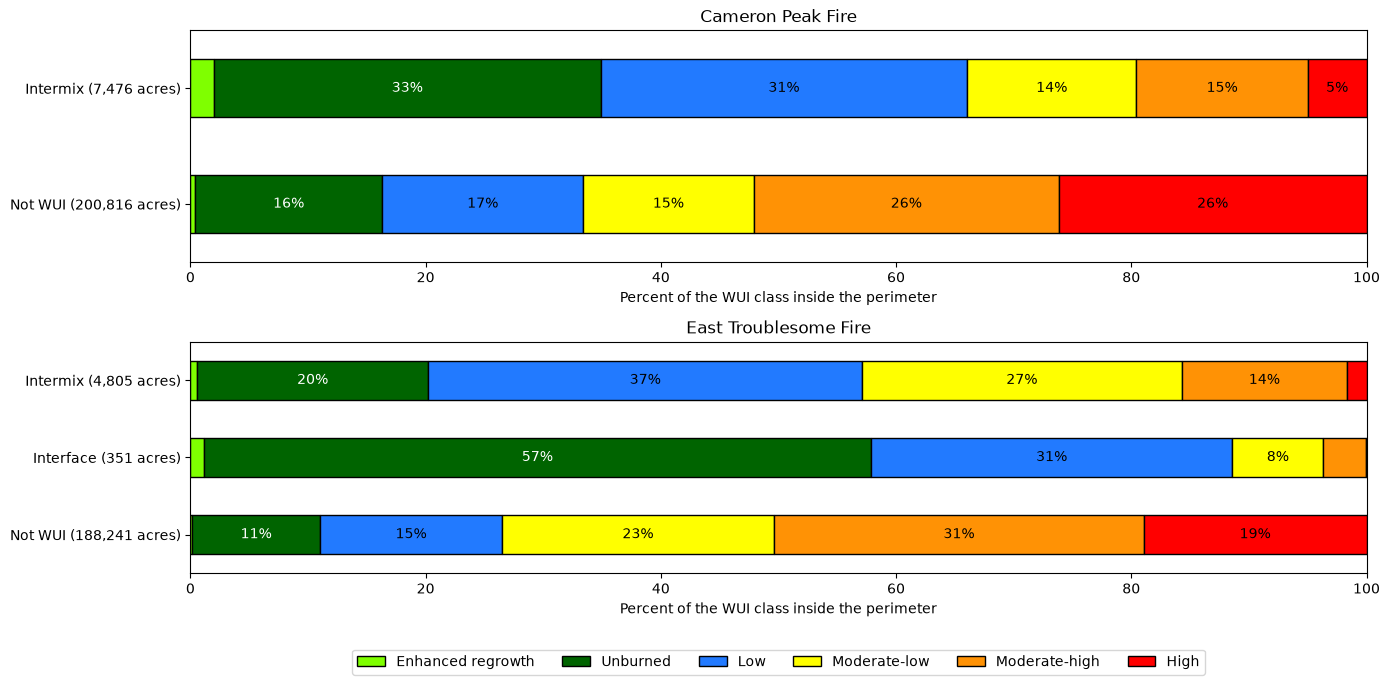

In [9]:
### plot the percent of each WUI class in each burn severity class
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for ax, fire in zip(axes, fire_keys):
    fire_df = wui_area_df[wui_area_df["fire"] == fire]

    ### percent of each WUI class in each burn severity class, leaving out WUI classes the fire doesn't have
    percent_df = fire_df.pivot_table(index="wui_class", columns="severity_class", values="percent_of_wui_class")
    percent_df = percent_df.reindex(index=["Intermix", "Interface", "Not WUI"], columns=class_names).dropna()

    ### label each bar with its area
    wui_acres = fire_df.groupby("wui_class")["acres"].sum()
    percent_df.index = [wui_class + " (" + format(wui_acres[wui_class], ",.0f") + " acres)" for wui_class in percent_df.index]

    percent_df.plot(kind="barh", stacked=True, color=[class_colors[name] for name in class_names], edgecolor="black", ax=ax, legend=False)

    ### write the percent in the classes wide enough to fit it
    for bars, name in zip(ax.containers, class_names):
        labels = [str(round(width)) + "%" if width >= 4 else "" for width in bars.datavalues]
        ax.bar_label(bars, labels=labels, label_type="center", color="white" if name == "Unburned" else "black")

    ### Intermix on top
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_title(fire.replace("_", " ").title() + " Fire")
    ax.set_xlabel("Percent of the WUI class inside the perimeter")
    ax.set_ylabel("")

### one legend for both fires
axes[1].legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.3))

plt.tight_layout()
plt.show()

Figure 1: Percent of each WUI class inside the perimeters in each Key and Benson class, with the area of each WUI class. Cameron Peak has no interface WUI inside its perimeter. 

# 3. High Severity in or Near the WUI
Fire can reach homes from outside the WUI, because embers can fly ahead of a fire. The 2.4km distance in the interface definition is an estimate of how far embers can fly ahead of a fire front (Radeloff et al., 2005), so the same distance is used here to find high severity area near the WUI.

The distance from each pixel to the nearest WUI pixel is found, counting the WUI outside the perimeters, and the high severity area is split into three groups: in the WUI, within 2.4km of the WUI, and more than 2.4km from the WUI. The study areas reach 5km past the perimeters, so all of the WUI within 2.4km of the fires is counted.

In the WUI map, the 2.4km is only used to decide which home areas count as interface. The WUI covers just the land where the homes are, so here the same distance is measured the other way, from the WUI out to the high severity area.

In [10]:
### the three distance groups, numbered 1 to 3
distance_names = ["In the WUI", "Within 2.4km of the WUI", "More than 2.4km from the WUI"]

### high severity area in each distance group
distance_rows = []
distance_groups = {}

for fire in fire_keys:

    ### distance from each pixel to the nearest WUI pixel (meters)
    distance_m = distance_transform_edt(wui_values[fire] == 0) * cell_size

    ### number each pixel by its distance group: 1 in the WUI, 2 within 2.4km, 3 farther
    distance_groups[fire] = np.full(distance_m.shape, 3)
    distance_groups[fire][distance_m <= ember_distance_m] = 2
    distance_groups[fire][distance_m == 0] = 1

    ### high severity pixels inside the perimeter
    high = inside_masks[fire] & (class_values[fire] == class_numbers["High"])

    for number, name in enumerate(distance_names, start=1):
        pixels = (high & (distance_groups[fire] == number)).sum()
        distance_rows.append({
            "fire": fire,
            "distance": name,
            "high_acres": pixels * cell_size**2 / m2_per_acre,
            "percent_of_high": pixels / high.sum() * 100,
        })

distance_df = pd.DataFrame(distance_rows)

### acres and percent of the high severity area in each distance group
distance_df.pivot_table(index="distance", columns="fire", values=["high_acres", "percent_of_high"], sort=False).round(1)

high_acres                  percent_of_high  \
fire                         cameron_peak east_troublesome    cameron_peak   
distance                                                                     
In the WUI                          373.8             79.8             0.7   
Within 2.4km of the WUI           14977.0           5091.5            28.3   
More than 2.4km from the WUI      37579.4          30566.2            71.0   

                                               
fire                         east_troublesome  
distance                                       
In the WUI                                0.2  
Within 2.4km of the WUI                  14.2  
More than 2.4km from the WUI             85.5

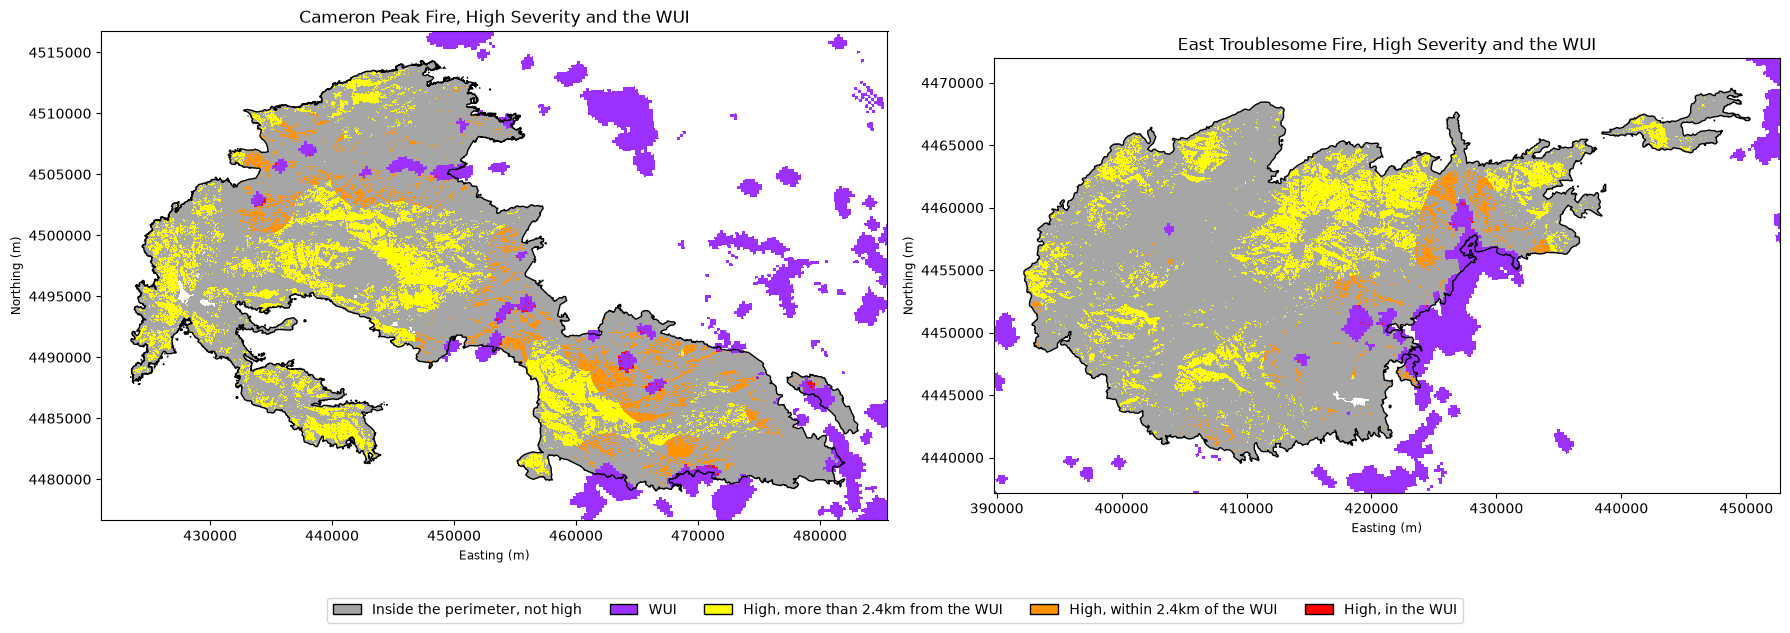

In [11]:
### map groups and colors
map_names = ["Inside the perimeter, not high", "WUI", "High, more than 2.4km from the WUI", "High, within 2.4km of the WUI", "High, in the WUI"]
map_colors = ["#a6a6a6", "#9b30ff", "#ffff00", "#ff9205", "#ff0000"]

### plot the high severity area by its distance to the WUI
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

for ax, fire in zip(axes, fire_keys):
    high = inside_masks[fire] & (class_values[fire] == class_numbers["High"])

    ### number each pixel by its map group (outside the perimeter and the WUI is left blank)
    map_values = np.full(class_values[fire].shape, np.nan)
    map_values[inside_masks[fire]] = 0
    map_values[wui_values[fire] > 0] = 1
    map_values[high & (distance_groups[fire] == 3)] = 2
    map_values[high & (distance_groups[fire] == 2)] = 3
    map_values[high & (distance_groups[fire] == 1)] = 4

    ax.imshow(map_values, cmap=ListedColormap(map_colors), vmin=-0.5, vmax=4.5, extent=extents[fire], interpolation="nearest")

    ### add the fire perimeter, and zoom to it with room for the WUI within 2.4km
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    perimeter.boundary.plot(ax=ax, color="black", linewidth=1)
    minx, miny, maxx, maxy = perimeter.total_bounds
    ax.set_xlim(minx - ember_distance_m, maxx + ember_distance_m)
    ax.set_ylim(miny - ember_distance_m, maxy + ember_distance_m)

    ax.ticklabel_format(style="plain")
    ax.set_title(fire.replace("_", " ").title() + " Fire, High Severity and the WUI")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

### one legend for both maps
handles = [Patch(facecolor=color, edgecolor="black", label=name) for name, color in zip(map_names, map_colors)]
fig.legend(handles=handles, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

Figure 2: High severity area inside the perimeters by its distance to the WUI, with the WUI (purple) and the NIFC perimeters (black). The high severity area in the WUI (red) is only 374 acres at Cameron Peak and 80 acres at East Troublesome, so it's too small to see at this scale.

# 4. Save the Results
The two area tables are saved to data/wui_severity.

In [12]:
### save the area of each burn severity class in each WUI class
wui_area_path = os.path.join(wui_severity_dir, "wui_severity_area.csv")
wui_area_df.to_csv(wui_area_path, index=False)

### save the high severity area by distance to the WUI
distance_path = os.path.join(wui_severity_dir, "high_severity_wui_distance.csv")
distance_df.to_csv(distance_path, index=False)

print("Saved WUI burn severity table to:", wui_area_path)
print("Saved high severity distance table to:", distance_path)

Saved WUI burn severity table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\wui_severity\wui_severity_area.csv
Saved high severity distance table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\wui_severity\high_severity_wui_distance.csv


# 5. Summary
29% of the high severity area at Cameron Peak and 14% at East Troublesome was in the WUI or within 2.4km of it, but very little was in the WUI itself:
- In the WUI: only 374 acres at Cameron Peak (0.7% of its high severity area) and 80 acres at East Troublesome (0.2%)
- Within 2.4km of the WUI: 14,977 acres at Cameron Peak (28%) and 5,092 acres at East Troublesome (14%), close enough for embers to reach homes. At Cameron Peak, most of it was in the Upper Buckhorn Creek, Middle Buckhorn Creek, and Black Hollow-Cache la Poudre River subwatersheds. At East Troublesome, over half of it was in the Onahu Creek-Colorado River subwatershed
- The WUI burned less severely than the land around it. 5% of the intermix inside the Cameron Peak perimeter burned at high severity, compared with 26% of the land outside the WUI. At East Troublesome it was 2% compared with 19%, and almost none of the interface burned at high severity (0.2 acres). About two thirds of the intermix at Cameron Peak, and over half at East Troublesome, was unburned or low severity (Figure 1)

The WUI likely burned less severely because homes are mostly built in valleys and clearings, with less dense forest around them. Burn severity only measures the vegetation, though, and homes can be lost to embers without the forest around them burning severely, so these numbers show where severe fire came close to homes, not how many homes burned.

# Citations
- Key, C. H., & Benson, N. C. (2006). Landscape assessment (LA): Sampling and analysis methods. In D. C. Lutes et al. (Eds.), *FIREMON: Fire effects monitoring and inventory system* (Gen. Tech. Rep. RMRS-GTR-164-CD, pp. LA-1-LA-55). USDA Forest Service, Rocky Mountain Research Station.
- Radeloff, V. C., Hammer, R. B., Stewart, S. I., Fried, J. S., Holcomb, S. S., & McKeefry, J. F. (2005). The wildland-urban interface in the United States. *Ecological Applications, 15*(3), 799-805. https://doi.org/10.1890/04-1413
- Warnock, M. (2026). *WUI Mapping Tool* (Version 1.0.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.23404697